# Training Models on Nonlinear Diffusion Dataset

Train and compare three models:
1. **FNO** (Fourier Neural Operator)
2. **U-Net** (Standard encoder-decoder)
3. **MRBNO** (Multilayer Reduced Basis Neural Operator)

on the nonlinear PDE: $-\nabla \cdot (e^{m(x)} \nabla u) = f$


## 1. Load Dataset and Imports


In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import sys
import os

# Add models directory to path
sys.path.append('models')

from FNO_model import FNO2d
from Unet_model import UNet
from MRBNO_model_multichannel import PCAReducerMultiChannel, MultiLayerReducedBasisResNetMultiChannel

print("Libraries imported successfully!")
print("IMPORTANT: If you get UNET errors, restart the kernel (Kernel -> Restart) to reload the fixed model!")


Libraries imported successfully!
IMPORTANT: If you get UNET errors, restart the kernel (Kernel -> Restart) to reload the fixed model!


In [2]:
# Load dataset
data = np.load('data/nonlinear_diffusion_dataset.npz')
f_all = data['f']  # (1000, 100, 100)
m_all = data['m']  # (1000, 100, 100)
u_all = data['u']  # (1000, 100, 100)
N = int(data['N'])
L = float(data['L'])

num_samples = f_all.shape[0]
print(f"Loaded {num_samples} samples")
print(f"Grid size: {N}x{N}")
print(f"Domain: [0, {L}]^2")

# Stack f and m as 2-channel input
X = np.stack([f_all, m_all], axis=1)  # (1000, 2, 100, 100)
Y = u_all  # (1000, 100, 100)

print(f"\nInput X shape: {X.shape}")
print(f"Output Y shape: {Y.shape}")


Loaded 1000 samples
Grid size: 100x100
Domain: [0, 1.0]^2

Input X shape: (1000, 2, 100, 100)
Output Y shape: (1000, 100, 100)


## 2. Normalize and Split Data


In [3]:
# Normalize
x_mean = X.mean()
x_std = X.std()
y_mean = Y.mean()
y_std = Y.std()

Xn = (X - x_mean) / (x_std + 1e-8)
Yn = (Y - y_mean) / (y_std + 1e-8)

print(f"X normalization: mean={x_mean:.4f}, std={x_std:.4f}")
print(f"Y normalization: mean={y_mean:.4f}, std={y_std:.4f}")

# Train/val split
train_frac = 0.7
n_train = int(train_frac * num_samples)

X_train, Y_train = Xn[:n_train], Yn[:n_train]
X_val, Y_val = Xn[n_train:], Yn[n_train:]

print(f"\nTraining samples: {len(X_train)}")
print(f"Validation samples: {len(X_val)}")


X normalization: mean=0.0379, std=1.7312
Y normalization: mean=0.0040, std=0.0888

Training samples: 700
Validation samples: 300


## 3. Prepare Data and PCA


In [4]:
# Convert to PyTorch tensors
X_train_t = torch.from_numpy(X_train).float()  # (700, 2, 100, 100)
Y_train_t = torch.from_numpy(Y_train).float().unsqueeze(1)  # (700, 1, 100, 100)
X_val_t = torch.from_numpy(X_val).float()  # (300, 2, 100, 100)
Y_val_t = torch.from_numpy(Y_val).float().unsqueeze(1)  # (300, 1, 100, 100)

print(f"Training data: X={X_train_t.shape}, Y={Y_train_t.shape}")
print(f"Validation data: X={X_val_t.shape}, Y={Y_val_t.shape}")

# Create data loaders
batch_size = 16
train_loader = DataLoader(TensorDataset(X_train_t, Y_train_t), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, Y_val_t), batch_size=batch_size, shuffle=False)

# Compute PCA for MRBNO with boundary condition awareness (switched off for now)
rb = PCAReducerMultiChannel(bc_weight=2.0, boundary_threshold=0.05, use_boundary_weighting=False).fit(Xn, Yn)
epsilon = 1e-5
k_in, k_out = rb.k_from_cutoff(j_in=1-1*epsilon, j_out=1-epsilon)

print(f"\nPCA components: k_in={k_in}, k_out={k_out}")
print(f"Boundary condition awareness: bc_weight={rb.bc_weight}, threshold={rb.boundary_threshold}")


Training data: X=torch.Size([700, 2, 100, 100]), Y=torch.Size([700, 1, 100, 100])
Validation data: X=torch.Size([300, 2, 100, 100]), Y=torch.Size([300, 1, 100, 100])

PCA components: k_in=122, k_out=61
Boundary condition awareness: bc_weight=2.0, threshold=0.05



PCA ANALYSIS AND SAMPLE VISUALIZATION


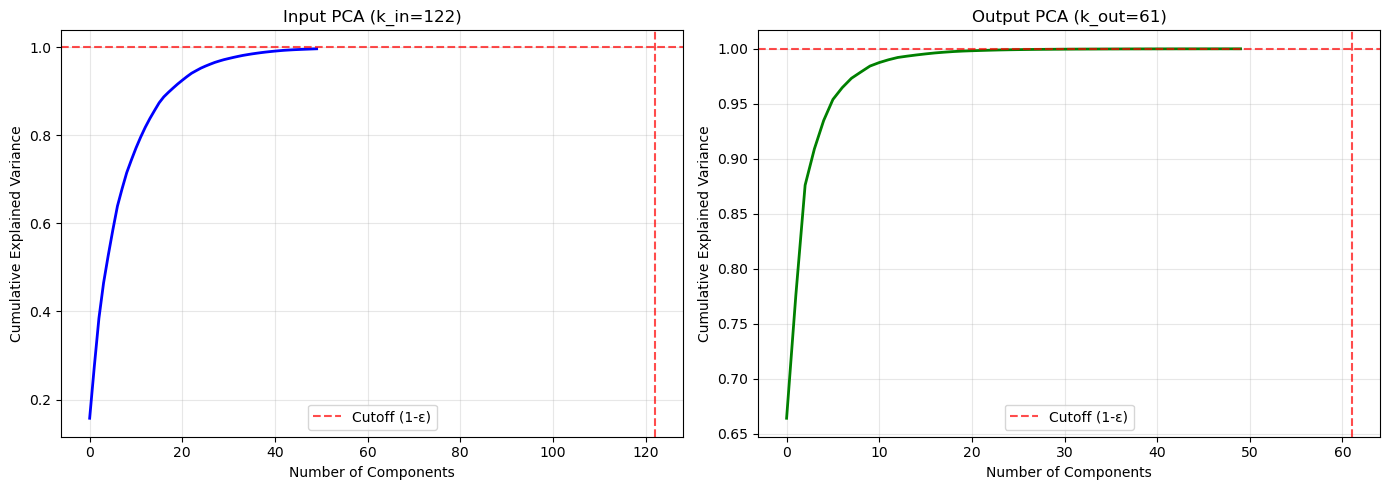

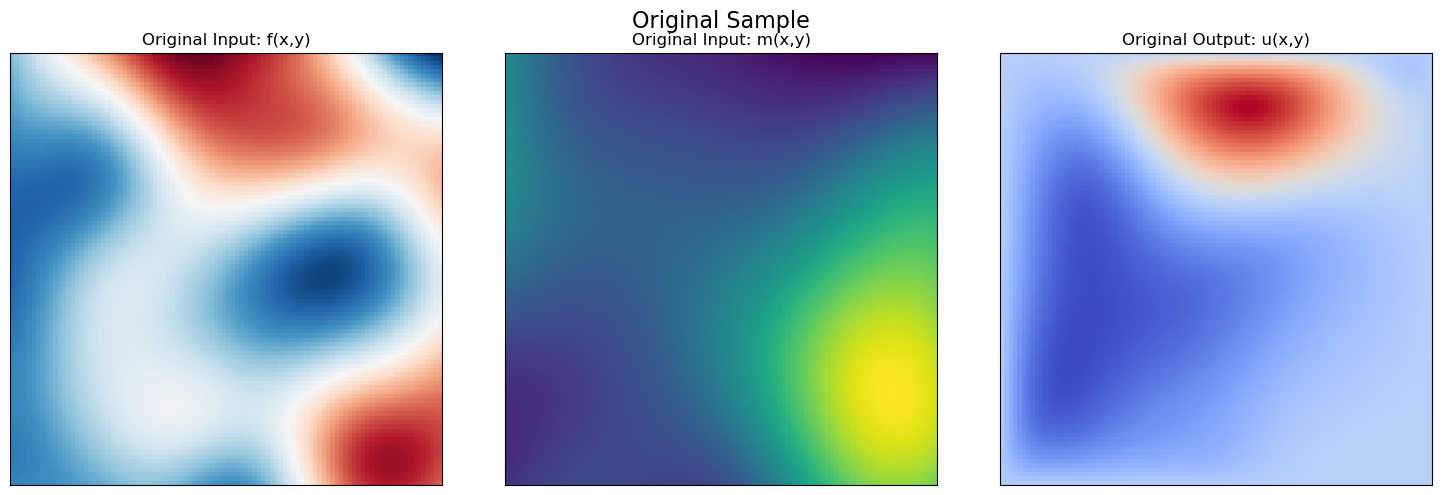

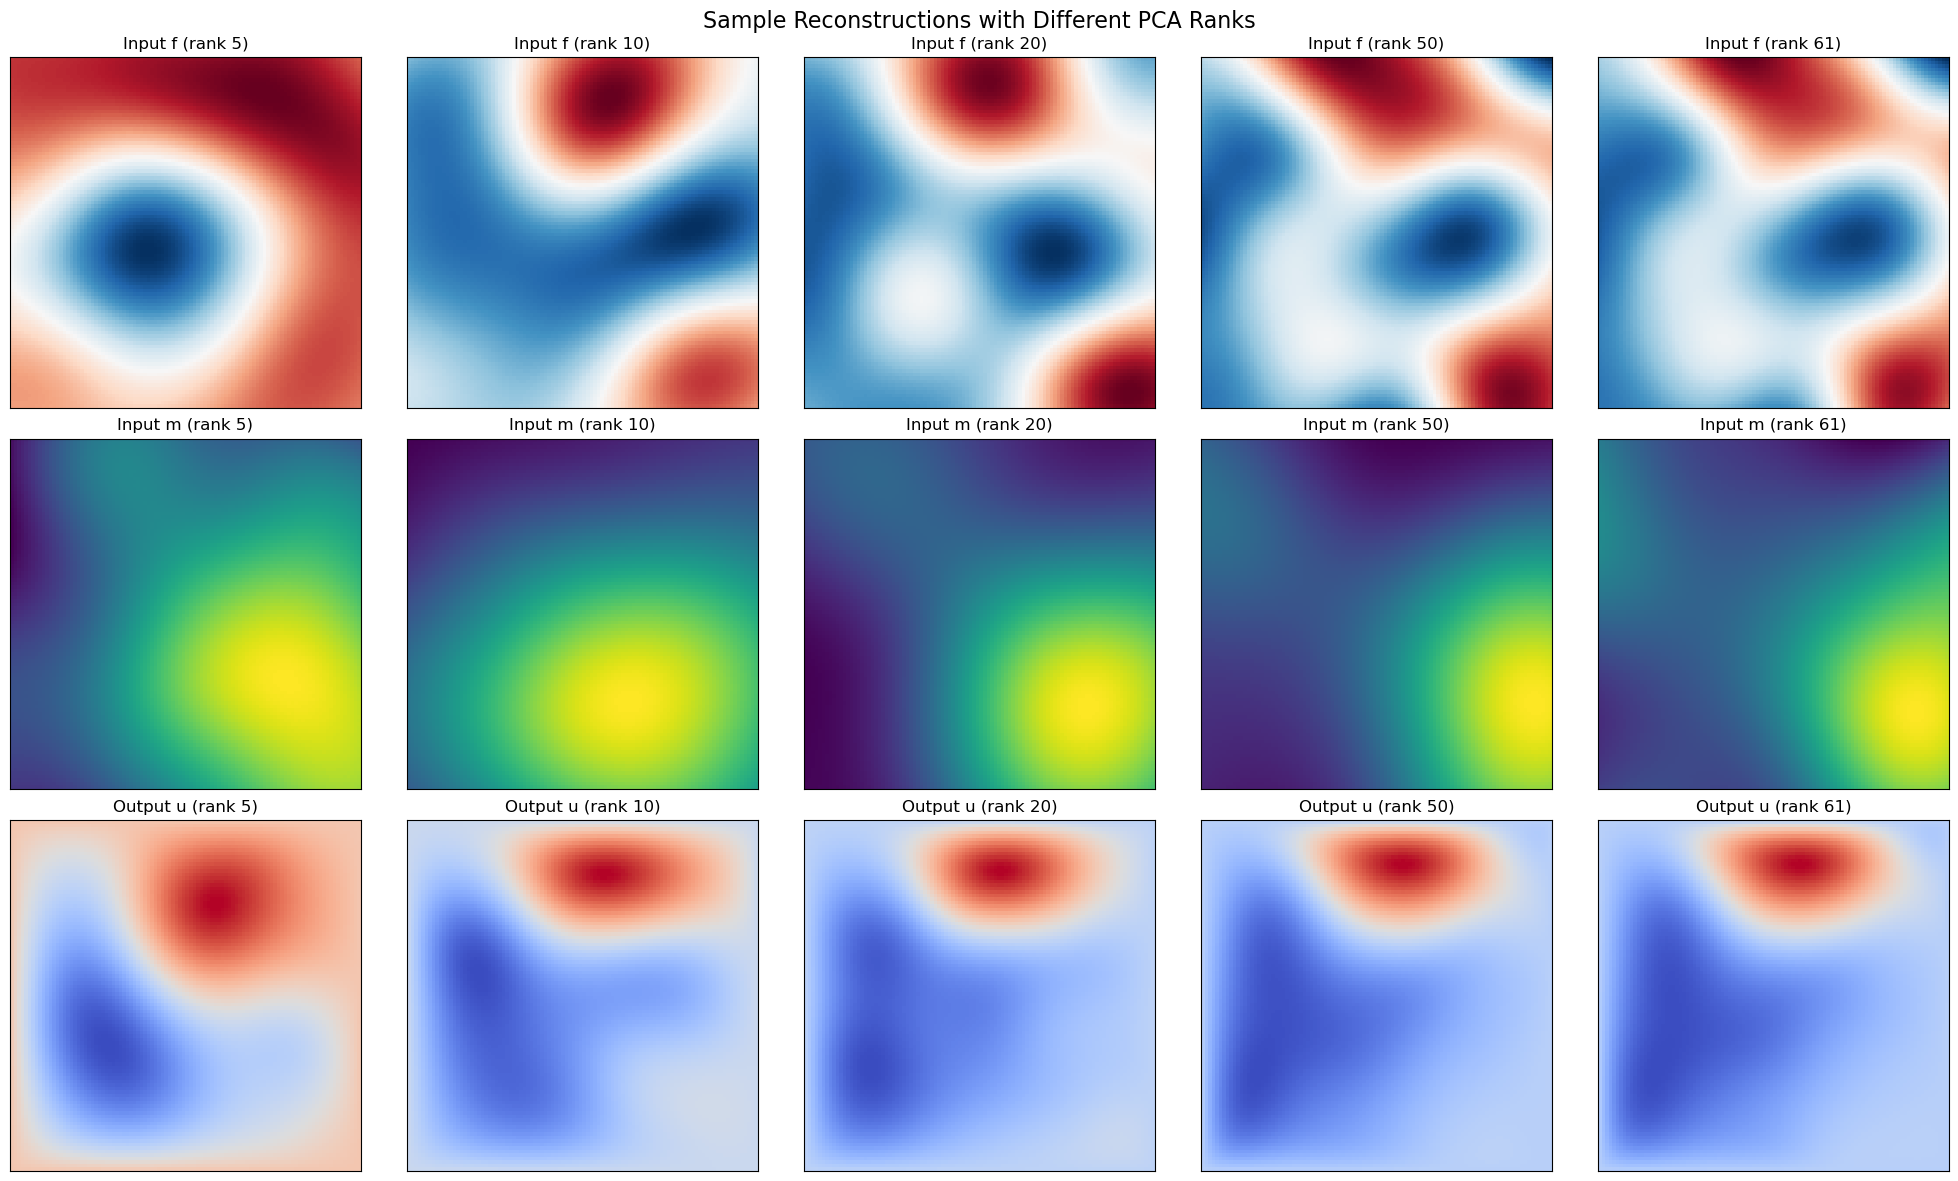


Reconstruction errors for sample 0:
Rank	Input MSE	Output MSE
-----------------------------------
5	7.11e-01	4.22e-03
10	2.70e-01	6.56e-04
20	7.23e-02	1.50e-04
50	4.09e-03	2.17e-06
61	1.24e-03	8.41e-07


In [5]:
# Visualize PCA components and sample reconstructions
print("\n" + "="*70)
print("PCA ANALYSIS AND SAMPLE VISUALIZATION")
print("="*70)

# Plot PCA explained variance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Input PCA variance
axes[0].plot(np.cumsum(rb.pca_in.explained_variance_ratio_[:50]), 'b-', linewidth=2)
axes[0].axhline(y=1-epsilon, color='r', linestyle='--', alpha=0.7, label=f'Cutoff (1-ε)')
axes[0].axvline(x=k_in, color='r', linestyle='--', alpha=0.7)
axes[0].set_xlabel('Number of Components')
axes[0].set_ylabel('Cumulative Explained Variance')
axes[0].set_title(f'Input PCA (k_in={k_in})')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Output PCA variance
axes[1].plot(np.cumsum(rb.pca_out.explained_variance_ratio_[:50]), 'g-', linewidth=2)
axes[1].axhline(y=1-epsilon, color='r', linestyle='--', alpha=0.7, label=f'Cutoff (1-ε)')
axes[1].axvline(x=k_out, color='r', linestyle='--', alpha=0.7)
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance')
axes[1].set_title(f'Output PCA (k_out={k_out})')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Visualize sample reconstructions with different ranks
sample_idx = 0
x_sample = Xn[sample_idx:sample_idx+1]  # (1, 2, 100, 100)
y_sample = Yn[sample_idx:sample_idx+1]  # (1, 100, 100)

# Show original sample first
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(x_sample[0, 0], origin='lower', cmap='RdBu_r')
axes[0].set_title('Original Input: f(x,y)')
axes[0].set_xticks([])
axes[0].set_yticks([])

axes[1].imshow(x_sample[0, 1], origin='lower', cmap='viridis')
axes[1].set_title('Original Input: m(x,y)')
axes[1].set_xticks([])
axes[1].set_yticks([])

axes[2].imshow(y_sample[0], origin='lower', cmap='coolwarm')
axes[2].set_title('Original Output: u(x,y)')
axes[2].set_xticks([])
axes[2].set_yticks([])

plt.suptitle('Original Sample', fontsize=16)
plt.tight_layout()
plt.show()

# Reconstruct with different numbers of components
ranks_to_test = [5, 10, 20, 50, k_out]

fig, axes = plt.subplots(3, len(ranks_to_test), figsize=(20, 12))

for i, rank in enumerate(ranks_to_test):
    # Input reconstruction - need to use full multi-channel input
    x_flat = x_sample.reshape(1, -1)  # Flatten all channels: (1, 20000)
    x_coeffs = rb.pca_in.transform(x_flat)[:, :rank]
    x_reconstructed = rb.pca_in.inverse_transform(
        np.pad(x_coeffs, ((0, 0), (0, rb.pca_in.n_components_ - rank)), 'constant')
    ).reshape(1, 2, 100, 100)
    
    # Show both input channels
    axes[0, i].imshow(x_reconstructed[0, 0], origin='lower', cmap='RdBu_r')
    axes[0, i].set_title(f'Input f (rank {rank})')
    axes[0, i].set_xticks([])
    axes[0, i].set_yticks([])
    
    axes[1, i].imshow(x_reconstructed[0, 1], origin='lower', cmap='viridis')
    axes[1, i].set_title(f'Input m (rank {rank})')
    axes[1, i].set_xticks([])
    axes[1, i].set_yticks([])
    
    # Output reconstruction
    y_flat = y_sample.reshape(1, -1)  # (1, 10000)
    y_coeffs = rb.pca_out.transform(y_flat)[:, :rank]
    y_reconstructed = rb.pca_out.inverse_transform(
        np.pad(y_coeffs, ((0, 0), (0, rb.pca_out.n_components_ - rank)), 'constant')
    ).reshape(100, 100)
    
    axes[2, i].imshow(y_reconstructed, origin='lower', cmap='coolwarm')
    axes[2, i].set_title(f'Output u (rank {rank})')
    axes[2, i].set_xticks([])
    axes[2, i].set_yticks([])

plt.suptitle('Sample Reconstructions with Different PCA Ranks', fontsize=16)
plt.tight_layout()
plt.show()

# Show reconstruction errors
print(f"\nReconstruction errors for sample {sample_idx}:")
print("Rank\tInput MSE\tOutput MSE")
print("-" * 35)
for rank in ranks_to_test:
    # Input error - use full multi-channel input
    x_flat = x_sample.reshape(1, -1)
    x_coeffs = rb.pca_in.transform(x_flat)[:, :rank]
    x_reconstructed = rb.pca_in.inverse_transform(
        np.pad(x_coeffs, ((0, 0), (0, rb.pca_in.n_components_ - rank)), 'constant')
    ).reshape(1, 2, 100, 100)
    x_mse = np.mean((x_reconstructed - x_sample)**2)
    
    # Output error
    y_flat = y_sample.reshape(1, -1)
    y_coeffs = rb.pca_out.transform(y_flat)[:, :rank]
    y_reconstructed = rb.pca_out.inverse_transform(
        np.pad(y_coeffs, ((0, 0), (0, rb.pca_out.n_components_ - rank)), 'constant')
    ).reshape(100, 100)
    y_mse = np.mean((y_reconstructed - y_sample[0])**2)
    
    print(f"{rank}\t{x_mse:.2e}\t{y_mse:.2e}")


## 4. Training Function


In [6]:
def train_model(model, train_loader, val_loader, epochs=100, lr=1e-3, device='cpu'):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-6)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.8)
    criterion = nn.MSELoss()
    
    train_losses = []
    val_losses = []
    best_val_loss = float('inf')
    
    for epoch in range(epochs):
        # Training
        model.train()
        train_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            train_loss += loss.item() * xb.size(0)
        train_loss /= len(train_loader.dataset)
        
        # Validation
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                pred = model(xb)
                loss = criterion(pred, yb)
                val_loss += loss.item() * xb.size(0)
        val_loss /= len(val_loader.dataset)
        
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
        
        scheduler.step()
        
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"[{epoch+1:03d}/{epochs}] train={train_loss:.4e} val={val_loss:.4e} lr={scheduler.get_last_lr()[0]:.2e} (best: {best_val_loss:.4e})")
    
    return train_losses, val_losses, best_val_loss


## 5. Train All Three Models


In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else 
                      "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cuda


## 5a. Train FNO Model


In [8]:
# Train FNO
print("\n" + "="*70)
print("TRAINING FNO")
print("="*70)
fno_model = FNO2d(in_channels=2, out_channels=1, width=32, modes=(16, 16), n_layers=4)
print(f"Parameters: {sum(p.numel() for p in fno_model.parameters()):,}")
fno_train_losses, fno_val_losses, fno_best_val = train_model(
    fno_model, train_loader, val_loader, epochs=150, lr=5e-3, device=device
)

# Save model
torch.save(fno_model.state_dict(), 'checkpoints/fno_nonlinear_best.pt')
print("FNO model saved to checkpoints/fno_nonlinear_best.pt")



TRAINING FNO
Parameters: 1,054,241
[001/150] train=5.3350e-01 val=1.3928e-01 lr=5.00e-03 (best: 1.3928e-01)
[010/150] train=4.8263e-02 val=5.3922e-02 lr=5.00e-03 (best: 4.6759e-02)
[020/150] train=3.0767e-02 val=4.4199e-02 lr=5.00e-03 (best: 3.8295e-02)
[030/150] train=2.6704e-02 val=3.0948e-02 lr=4.00e-03 (best: 3.0948e-02)
[040/150] train=9.1368e-03 val=2.9446e-02 lr=4.00e-03 (best: 2.9446e-02)
[050/150] train=1.0601e-02 val=2.9474e-02 lr=4.00e-03 (best: 2.7985e-02)
[060/150] train=1.4095e-02 val=3.2786e-02 lr=3.20e-03 (best: 2.7826e-02)
[070/150] train=1.1717e-02 val=2.6926e-02 lr=3.20e-03 (best: 2.5549e-02)
[080/150] train=1.0464e-02 val=2.5648e-02 lr=3.20e-03 (best: 2.4660e-02)
[090/150] train=1.3503e-02 val=2.7091e-02 lr=2.56e-03 (best: 2.3845e-02)
[100/150] train=6.8929e-03 val=2.6117e-02 lr=2.56e-03 (best: 2.3845e-02)
[110/150] train=1.3845e-02 val=3.0036e-02 lr=2.56e-03 (best: 2.3845e-02)
[120/150] train=6.1272e-03 val=2.6586e-02 lr=2.05e-03 (best: 2.3206e-02)
[130/150] train

## 5b. Train U-Net Model


In [9]:
# Train U-Net
print("\n" + "="*70)
print("TRAINING U-NET")
print("="*70)
unet_model = UNet(in_channels=2, out_channels=1, base_features=32, depth=3, bilinear=True)
print(f"Parameters: {sum(p.numel() for p in unet_model.parameters()):,}")
unet_train_losses, unet_val_losses, unet_best_val = train_model(
    unet_model, train_loader, val_loader, epochs=150, lr=5e-3, device=device
)

# Save model
torch.save(unet_model.state_dict(), 'checkpoints/unet_nonlinear_best.pt')
print("U-Net model saved to checkpoints/unet_nonlinear_best.pt")



TRAINING U-NET
Parameters: 1,949,409
[001/150] train=6.2594e-01 val=7.6536e+00 lr=5.00e-03 (best: 7.6536e+00)
[010/150] train=3.5522e-01 val=1.1020e-01 lr=5.00e-03 (best: 7.1851e-02)
[020/150] train=3.7566e-01 val=1.0365e-01 lr=5.00e-03 (best: 4.9363e-02)
[030/150] train=3.5325e-01 val=1.1561e-01 lr=4.00e-03 (best: 4.9363e-02)
[040/150] train=2.9685e-01 val=8.9633e-02 lr=4.00e-03 (best: 3.5340e-02)
[050/150] train=2.4635e-01 val=5.8207e-02 lr=4.00e-03 (best: 3.3880e-02)
[060/150] train=2.5812e-01 val=4.8914e-02 lr=3.20e-03 (best: 3.2135e-02)
[070/150] train=2.2791e-01 val=5.4795e-02 lr=3.20e-03 (best: 3.0501e-02)
[080/150] train=2.4506e-01 val=3.9764e-02 lr=3.20e-03 (best: 3.0501e-02)
[090/150] train=2.2296e-01 val=1.7623e-01 lr=2.56e-03 (best: 3.0501e-02)
[100/150] train=1.7756e-01 val=4.2335e-02 lr=2.56e-03 (best: 3.0501e-02)
[110/150] train=1.5977e-01 val=6.2761e-02 lr=2.56e-03 (best: 3.0501e-02)
[120/150] train=1.3617e-01 val=3.2877e-02 lr=2.05e-03 (best: 2.9476e-02)
[130/150] tra

## 5c. Train MRBNO Model


In [19]:
# Train MRBNO
print("\n" + "="*70)
print("TRAINING MRBNO")
print("="*70)

# k_in = int(k_in/2)
# k_out = 2*k_out
# Calculate target parameters to match FNO/U-Net
# FNO: ~1.2M params, U-Net: ~1.1M params
# Adjust MRBNO parameters to be comparable
target_params = 1200000  # Target around 1.2M parameters

# Start with reasonable defaults and adjust
mrbno_model = MultiLayerReducedBasisResNetMultiChannel(
    rb=rb, k_in=k_in, k_out=k_out, layers=2, hidden=768, depth=1,
    use_skip_connections=True, dropout=0.3, block0_dropout=0.2
)

current_params = sum(p.numel() for p in mrbno_model.parameters())
print(f"Initial MRBNO parameters: {current_params:,}")

# # Adjust parameters to match target
# if current_params < target_params * 0.8:
#     # Increase model size
#     mrbno_model = MultiLayerReducedBasisResNetMultiChannel(
#         rb=rb, k_in=k_in, k_out=k_out, layers=4, hidden=160, depth=4,
#         use_skip_connections=True
#     )
# elif current_params > target_params * 1.2:
#     # Decrease model size
#     mrbno_model = MultiLayerReducedBasisResNetMultiChannel(
#         rb=rb, k_in=k_in, k_out=k_out, layers=2, hidden=96, depth=2,
#         use_skip_connections=True
#     )

final_params = sum(p.numel() for p in mrbno_model.parameters())
print(f"Final MRBNO parameters: {final_params:,}")

mrbno_train_losses, mrbno_val_losses, mrbno_best_val = train_model(
    mrbno_model, train_loader, val_loader, epochs=500, lr=5e-3, device=device
)

# Save model
torch.save(mrbno_model.state_dict(), 'checkpoints/mrbno_nonlinear_best.pt')
print("MRBNO model saved to checkpoints/mrbno_nonlinear_best.pt")

print("\n" + "="*70)
print("TRAINING COMPLETE!")
print("="*70)



TRAINING MRBNO
Initial MRBNO parameters: 4,511,199
Final MRBNO parameters: 4,511,199
[001/500] train=9.2534e-01 val=5.0654e-01 lr=5.00e-03 (best: 5.0654e-01)
[010/500] train=4.4913e-01 val=3.2713e-01 lr=5.00e-03 (best: 2.9949e-01)
[020/500] train=5.4793e-01 val=2.7626e-01 lr=5.00e-03 (best: 2.7101e-01)
[030/500] train=3.9945e-01 val=2.7437e-01 lr=4.00e-03 (best: 2.1759e-01)
[040/500] train=1.5591e-01 val=1.3595e-01 lr=4.00e-03 (best: 1.3595e-01)
[050/500] train=1.4512e-01 val=1.3782e-01 lr=4.00e-03 (best: 1.3022e-01)
[060/500] train=1.3385e-01 val=1.3115e-01 lr=3.20e-03 (best: 1.1305e-01)
[070/500] train=6.2327e-02 val=1.0662e-01 lr=3.20e-03 (best: 1.0303e-01)
[080/500] train=3.1433e-02 val=9.0171e-02 lr=3.20e-03 (best: 8.7367e-02)
[090/500] train=6.5076e-02 val=9.6925e-02 lr=2.56e-03 (best: 8.7367e-02)
[100/500] train=4.5133e-02 val=9.4511e-02 lr=2.56e-03 (best: 7.6904e-02)
[110/500] train=3.8025e-02 val=8.0209e-02 lr=2.56e-03 (best: 7.0281e-02)
[120/500] train=3.9940e-02 val=8.0534e

In [20]:
# Fixed version of the results summary
print("\n" + "="*70)
print("RESULTS SUMMARY")
print("="*70)
print(f"\nFNO:   Best Val Loss = {fno_best_val:.6e}, RMSE = {np.sqrt(fno_best_val):.6e}")
print(f"U-Net: Best Val Loss = {unet_best_val:.6e}, RMSE = {np.sqrt(unet_best_val):.6e}")
print(f"MRBNO: Best Val Loss = {mrbno_best_val:.6e}, RMSE = {np.sqrt(mrbno_best_val):.6e}")

print(f"\nMRBNO Architecture Details:")
print(f"- Uses skip connections: {mrbno_model.use_skip_connections}")
print(f"- Layers: {mrbno_model.layers}")
print(f"- Hidden dimension: {mrbno_model.blocks[0].in_proj.out_features if mrbno_model.blocks else 'N/A'}")
print(f"- PCA ranks: k_in={k_in}, k_out={k_out}")
print(f"- Block 0: Input basis → Output basis (transforms 2-channel to 1-channel)")
print(f"- Blocks 1+: Output basis → Output basis (FNO-style residuals)")
print(f"- Boundary-aware PCA: bc_weight={rb.bc_weight}, threshold={rb.boundary_threshold}, enabled={rb.use_boundary_weighting}")
print(f"- Residual pattern: y = y + gate(block(y)) (FNO-style)")



RESULTS SUMMARY

FNO:   Best Val Loss = 2.221619e-02, RMSE = 1.490510e-01
U-Net: Best Val Loss = 2.497216e-02, RMSE = 1.580258e-01
MRBNO: Best Val Loss = 5.523191e-02, RMSE = 2.350147e-01

MRBNO Architecture Details:
- Uses skip connections: True
- Layers: 2
- Hidden dimension: 768
- PCA ranks: k_in=30, k_out=244
- Block 0: Input basis → Output basis (transforms 2-channel to 1-channel)
- Blocks 1+: Output basis → Output basis (FNO-style residuals)
- Boundary-aware PCA: bc_weight=2.0, threshold=0.05, enabled=False
- Residual pattern: y = y + gate(block(y)) (FNO-style)


## 6. Compare Results



MODEL PARAMETER COMPARISON
FNO:   1,054,241 parameters
U-Net: 1,949,409 parameters
MRBNO: 4,511,199 parameters

Parameter ratios:
FNO/U-Net:   0.54
MRBNO/U-Net: 2.31
MRBNO/FNO:   4.28


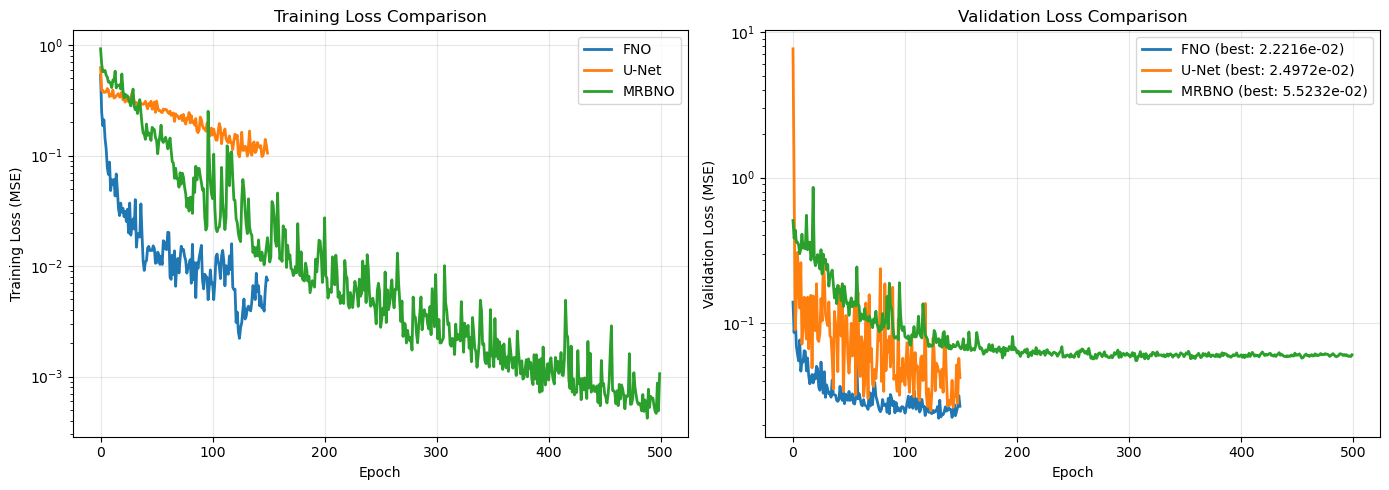


RESULTS SUMMARY

FNO:   Best Val Loss = 2.221619e-02, RMSE = 1.490510e-01
U-Net: Best Val Loss = 2.497216e-02, RMSE = 1.580258e-01
MRBNO: Best Val Loss = 5.523191e-02, RMSE = 2.350147e-01

MRBNO Architecture Details:
- Uses skip connections: True
- Layers: 2
- PCA ranks: k_in=30, k_out=244
- All blocks after first use output basis for fair comparison


In [21]:
# Print parameter comparison
print("\n" + "="*70)
print("MODEL PARAMETER COMPARISON")
print("="*70)
fno_params = sum(p.numel() for p in fno_model.parameters())
unet_params = sum(p.numel() for p in unet_model.parameters())
mrbno_params = sum(p.numel() for p in mrbno_model.parameters())

print(f"FNO:   {fno_params:,} parameters")
print(f"U-Net: {unet_params:,} parameters") 
print(f"MRBNO: {mrbno_params:,} parameters")
print(f"\nParameter ratios:")
print(f"FNO/U-Net:   {fno_params/unet_params:.2f}")
print(f"MRBNO/U-Net: {mrbno_params/unet_params:.2f}")
print(f"MRBNO/FNO:   {mrbno_params/fno_params:.2f}")

# Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fno_train_losses, label='FNO', linewidth=2)
axes[0].plot(unet_train_losses, label='U-Net', linewidth=2)
axes[0].plot(mrbno_train_losses, label='MRBNO', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Training Loss (MSE)')
axes[0].set_title('Training Loss Comparison')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_yscale('log')

axes[1].plot(fno_val_losses, label=f'FNO (best: {fno_best_val:.4e})', linewidth=2)
axes[1].plot(unet_val_losses, label=f'U-Net (best: {unet_best_val:.4e})', linewidth=2)
axes[1].plot(mrbno_val_losses, label=f'MRBNO (best: {mrbno_best_val:.4e})', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Validation Loss (MSE)')
axes[1].set_title('Validation Loss Comparison')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

# Print summary
print("\n" + "="*70)
print("RESULTS SUMMARY")
print("="*70)
print(f"\nFNO:   Best Val Loss = {fno_best_val:.6e}, RMSE = {np.sqrt(fno_best_val):.6e}")
print(f"U-Net: Best Val Loss = {unet_best_val:.6e}, RMSE = {np.sqrt(unet_best_val):.6e}")
print(f"MRBNO: Best Val Loss = {mrbno_best_val:.6e}, RMSE = {np.sqrt(mrbno_best_val):.6e}")

print(f"\nMRBNO Architecture Details:")
print(f"- Uses skip connections: {mrbno_model.use_skip_connections}")
print(f"- Layers: {mrbno_model.layers}")
# print(f"- Hidden dimension: {mrbno_model.blocks[0].hidden if mrbno_model.blocks else 'N/A'}")
print(f"- PCA ranks: k_in={k_in}, k_out={k_out}")
print(f"- All blocks after first use output basis for fair comparison")


## 7. Visualize Predictions


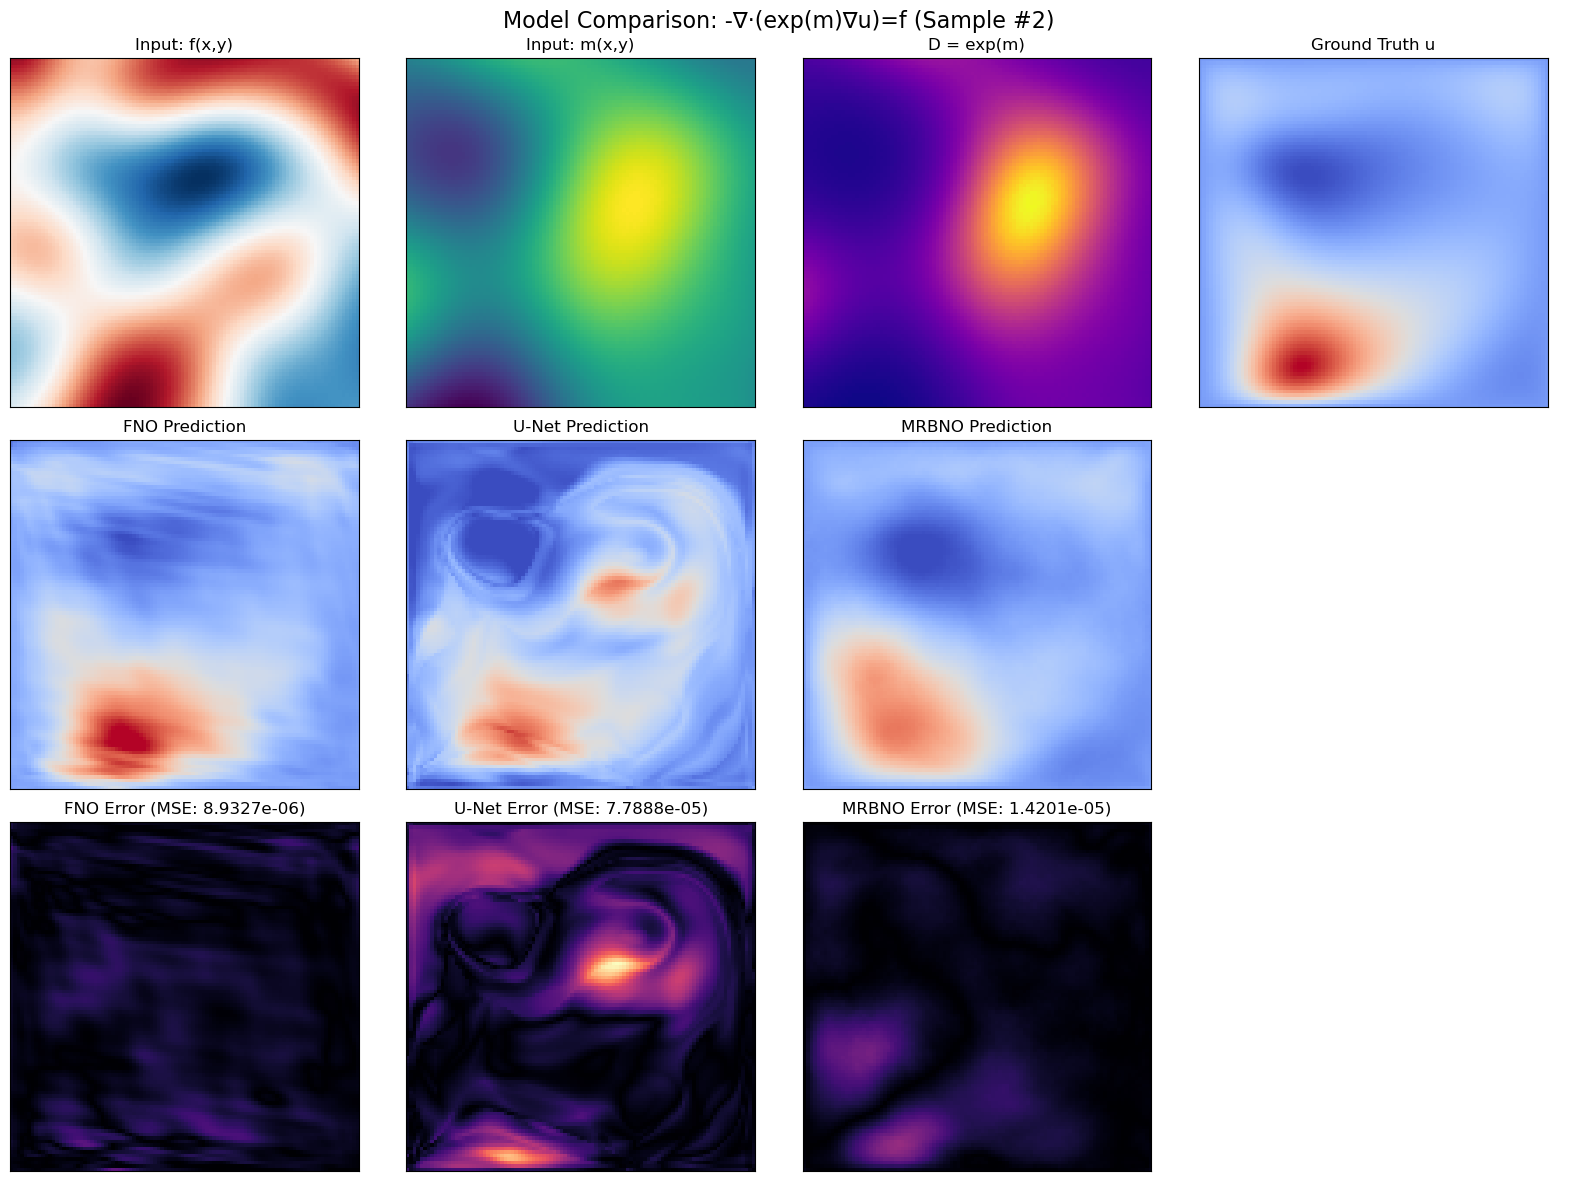

In [22]:
# Pick validation sample and get predictions
idx = 2
x_sample = X_val_t[idx:idx+1].to(device)
y_true = Y_val_t[idx].cpu().numpy()[0]

fno_model.eval()
unet_model.eval()
mrbno_model.eval()

with torch.no_grad():
    fno_pred = fno_model(x_sample).cpu().numpy()[0, 0]
    unet_pred = unet_model(x_sample).cpu().numpy()[0, 0]
    mrbno_pred = mrbno_model(x_sample).cpu().numpy()[0, 0]

# Denormalize
f_sample = (x_sample[0, 0].cpu().numpy() * x_std + x_mean)
m_sample = (x_sample[0, 1].cpu().numpy() * x_std + x_mean)
y_true_denorm = y_true * y_std + y_mean
fno_pred_denorm = fno_pred * y_std + y_mean
unet_pred_denorm = unet_pred * y_std + y_mean
mrbno_pred_denorm = mrbno_pred * y_std + y_mean

# Plot
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

# Row 1: Inputs
axes[0, 0].imshow(f_sample, origin='lower', cmap='RdBu_r')
axes[0, 0].set_title('Input: f(x,y)')
axes[0, 1].imshow(m_sample, origin='lower', cmap='viridis')
axes[0, 1].set_title('Input: m(x,y)')
axes[0, 2].imshow(np.exp(m_sample), origin='lower', cmap='plasma')
axes[0, 2].set_title('D = exp(m)')
axes[0, 3].imshow(y_true_denorm, origin='lower', cmap='coolwarm')
axes[0, 3].set_title('Ground Truth u')

# Row 2: Predictions
vmin, vmax = y_true_denorm.min(), y_true_denorm.max()
axes[1, 0].imshow(fno_pred_denorm, origin='lower', cmap='coolwarm', vmin=vmin, vmax=vmax)
axes[1, 0].set_title('FNO Prediction')
axes[1, 1].imshow(unet_pred_denorm, origin='lower', cmap='coolwarm', vmin=vmin, vmax=vmax)
axes[1, 1].set_title('U-Net Prediction')
axes[1, 2].imshow(mrbno_pred_denorm, origin='lower', cmap='coolwarm', vmin=vmin, vmax=vmax)
axes[1, 2].set_title('MRBNO Prediction')
axes[1, 3].axis('off')

# Row 3: Errors
fno_err = np.abs(fno_pred_denorm - y_true_denorm)
unet_err = np.abs(unet_pred_denorm - y_true_denorm)
mrbno_err = np.abs(mrbno_pred_denorm - y_true_denorm)
err_max = max(fno_err.max(), unet_err.max(), mrbno_err.max())

axes[2, 0].imshow(fno_err, origin='lower', cmap='magma', vmin=0, vmax=err_max)
axes[2, 0].set_title(f'FNO Error (MSE: {np.mean(fno_err**2):.4e})')
axes[2, 1].imshow(unet_err, origin='lower', cmap='magma', vmin=0, vmax=err_max)
axes[2, 1].set_title(f'U-Net Error (MSE: {np.mean(unet_err**2):.4e})')
axes[2, 2].imshow(mrbno_err, origin='lower', cmap='magma', vmin=0, vmax=err_max)
axes[2, 2].set_title(f'MRBNO Error (MSE: {np.mean(mrbno_err**2):.4e})')
axes[2, 3].axis('off')

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(f'Model Comparison: -∇·(exp(m)∇u)=f (Sample #{idx})', fontsize=16)
plt.tight_layout()
plt.show()


## Skip Connection Strategies in MRBNO

The MRBNO model now uses FNO-style skip connections:

1. **Block 0**: Transforms 2-channel input to 1-channel output (input basis → output basis)
2. **FNO-style Residuals**: Each subsequent block uses residual connections (y = y + gate(block(y)))
3. **Configurable**: Skip connections can be enabled/disabled via `use_skip_connections` parameter

### Skip Connection Benefits:
- **Gradient Flow**: Helps with vanishing gradient problem in deep networks
- **Identity Mapping**: Allows the model to learn identity transformations
- **Stability**: Improves training stability and convergence
- **Expressiveness**: Enables the model to learn both fine-grained and coarse-grained features

### Architecture Flow:
```
Input (2-channel) → Block 0 (input→output basis) → 1-channel output
                ↓
                Blocks 1+ (output basis → output basis) → FNO-style residuals
                ↓
                Final Output (1-channel)
```
